# BOOK CLASSIFIER - FICTION vs NONFICTION

### **Importing libraries and functions**

In [1]:
import requests
from bs4 import BeautifulSoup as bs
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from functions import retrieve_data, find_details, calc_books_pages, gather_data_books

### **Web scraping**

Send a HTTP request to the website "Books to Scrape" and used BeautifulSoup to get the data.

In [2]:
r = requests.get('http://books.toscrape.com')
if r.status_code == 200:
    print('Success')
    soup = bs(r.content, 'html.parser')
else:
    print('Error')

Success


Found the links for the starting pages for both fiction and nonfiction books.

In [3]:
link_list = soup.find('ul', class_="nav-list")
links = link_list.find_all('a')
category_link = {}
for l in links:
    category = l.text.strip()
    link_to_category = l.get("href")
    if category == "Fiction":
        category_link["Fiction"] = 'http://books.toscrape.com/' + link_to_category
    elif category == "Nonfiction":
        category_link["Nonfiction"] = 'http://books.toscrape.com/' + link_to_category

print(category_link)

{'Fiction': 'http://books.toscrape.com/catalogue/category/books/fiction_10/index.html', 'Nonfiction': 'http://books.toscrape.com/catalogue/category/books/nonfiction_13/index.html'}


### **Fiction books**

In [4]:
soupf = retrieve_data(category_link["Fiction"])

In [5]:
data_books_fiction = []

fiction = soupf.find('ol', class_="row")
books_fiction = fiction.find_all('h3')
gather_data_books(books_fiction, 'http://books.toscrape.com/catalogue/', soupf,
                    data_books_fiction, "fiction")

nr_books_fiction, nr_pages_fiction = calc_books_pages(soupf)
print(f"There are {nr_pages_fiction} pages of fiction books.")
print(f"There are {nr_books_fiction} fiction books in total.")

for page in range(2, int(nr_pages_fiction) + 1):
    fiction_link = category_link["Fiction"].replace("index.html", "") + f'page-{page}.html'
    soupbf = retrieve_data(fiction_link)
    fiction = soupbf.find('ol', class_="row")
    books_fiction = fiction.find_all('h3')
    gather_data_books(books_fiction, 'http://books.toscrape.com/catalogue/', soupbf,
                        data_books_fiction, "fiction")

print("\nDetails of the first 3 fiction books:")
for i in range(3):
    print(data_books_fiction[i])
print("\nDetails of the last 3 fiction books:")
for i in range(1,4):
    print(data_books_fiction[-4+i])

There are 4 pages of fiction books.
There are 65 fiction books in total.

Details of the first 3 fiction books:
{'title': 'Soumission', 'image': 'http://books.toscrape.com/media/cache/ee/cf/eecfe998905e455df12064dba399c075.jpg', 'description': 'Dans une France assez proche de la nôtre, un homme s’engage dans la carrière universitaire. Peu motivé par l’enseignement, il s’attend à une vie ennuyeuse mais calme, protégée des grands drames historiques. Cependant les forces en jeu dans le pays ont fissuré le système politique jusqu’à provoquer son effondrement. Cette implosion sans soubresauts, sans vraie révolution, s Dans une France assez proche de la nôtre, un homme s’engage dans la carrière universitaire. Peu motivé par l’enseignement, il s’attend à une vie ennuyeuse mais calme, protégée des grands drames historiques. Cependant les forces en jeu dans le pays ont fissuré le système politique jusqu’à provoquer son effondrement. Cette implosion sans soubresauts, sans vraie révolution, se dé

### **Nonfiction books**

In [6]:
soupnf = retrieve_data(category_link["Nonfiction"])

In [ ]:
data_books_nonfiction = []

nonfiction = soupnf.find('ol', class_="row")
books_nonfiction = nonfiction.find_all('h3')
gather_data_books(books_nonfiction, 'http://books.toscrape.com/catalogue/', soupnf,
                      data_books_nonfiction, "nonfiction")

nr_books_nonfiction, nr_pages_nonfiction = calc_books_pages(soupnf)
print(f"There are {nr_pages_nonfiction} pages of nonfiction books.")
print(f"There are {nr_books_nonfiction} nonfiction books in total.")

for page in range(2, int(nr_pages_nonfiction) + 1):
    nonfiction_link = category_link["Nonfiction"].replace("index.html", "") + f'page-{page}.html'
    soupbnf = retrieve_data(nonfiction_link)

    nonfiction = soupbnf.find('ol', class_="row")
    books_nonfiction = nonfiction.find_all('h3')
    gather_data_books(books_nonfiction, 'http://books.toscrape.com/catalogue/', soupbnf,
                      data_books_nonfiction, "nonfiction")

print("\nDetails of the first 3 nonfiction books:")
for i in range(3):
    print(data_books_nonfiction[i])
print("\nDetails of the last 3 nonfiction books:")
for i in range(1,4):
    print(data_books_nonfiction[-4+i])

There are 6 pages of fiction books.
There are 110 fiction books in total.

Details of the first 3 nonfiction books:
{'title': 'Worlds Elsewhere: Journeys Around Shakespeare’s Globe', 'image': 'http://books.toscrape.com/media/cache/7b/d9/7bd93db091d736d0c6ff9d578e3ba3d7.jpg', 'description': 'Anti-apartheid activist, Bollywood screenwriter, Nazi pin-up, hero of the Wild West: this is Shakespeare as you have never seen him before.From the sixteenth-century Baltic to the American Revolution, from colonial India to the skyscrapers of modern-day Shanghai, Shakespeare’s plays appear at the most fascinating of times and in the most unexpected of places. No other writ Anti-apartheid activist, Bollywood screenwriter, Nazi pin-up, hero of the Wild West: this is Shakespeare as you have never seen him before.From the sixteenth-century Baltic to the American Revolution, from colonial India to the skyscrapers of modern-day Shanghai, Shakespeare’s plays appear at the most fascinating of times and in t

### **Building the dataset**

In [8]:
data_books = data_books_fiction + data_books_nonfiction
df_books = pd.DataFrame(data_books)
df_books["text"] = df_books["title"] + " " + df_books["description"]
df_books.to_csv("dataset_books.csv", index=False)
df_books.head(10)

,title,image,description,category,text
0,Soumission,http://books.toscrape.com/media/cache/ee/cf/ee...,"Dans une France assez proche de la nôtre, un h...",fiction,Soumission Dans une France assez proche de la ...
1,Private Paris (Private #10),http://books.toscrape.com/media/cache/05/87/05...,Paris is burning--and only Private's Jack Morg...,fiction,Private Paris (Private #10) Paris is burning--...
2,"We Love You, Charlie Freeman",http://books.toscrape.com/media/cache/87/a2/87...,"The Freeman family--Charles, Laurel, and their...",fiction,"We Love You, Charlie Freeman The Freeman famil..."
3,Thirst,http://books.toscrape.com/media/cache/8c/54/8c...,"On a searing summer Friday, Eddie Chapman has ...",fiction,"Thirst On a searing summer Friday, Eddie Chapm..."
4,The Murder That Never Was (Forensic Instincts #5),http://books.toscrape.com/media/cache/29/e0/29...,"Given the opportunity, would you assume someon...",fiction,The Murder That Never Was (Forensic Instincts ...
5,Tuesday Nights in 1980,http://books.toscrape.com/media/cache/a3/ad/a3...,"“In one sentence, Ms. Prentiss captures a sens...",fiction,"Tuesday Nights in 1980 “In one sentence, Ms. P..."
6,The Vacationers,http://books.toscrape.com/media/cache/34/c9/34...,"An irresistible, deftly observed novel about t...",fiction,"The Vacationers An irresistible, deftly observ..."
7,The Regional Office Is Under Attack!,http://books.toscrape.com/media/cache/d4/73/d4...,In a world beset by amassing forces of darknes...,fiction,The Regional Office Is Under Attack! In a worl...
8,Finders Keepers (Bill Hodges Trilogy #2),http://books.toscrape.com/media/cache/76/80/76...,"A masterful, intensely suspenseful novel about...",fiction,Finders Keepers (Bill Hodges Trilogy #2) A mas...
9,The Time Keeper,http://books.toscrape.com/media/cache/37/d1/37...,"In this fable, the first man on earth to count...",fiction,"The Time Keeper In this fable, the first man o..."


In [9]:
df_books["category"].value_counts()

category
nonfiction    110
fiction        65
Name: count, dtype: int64

The data is unbalanced: 63% nonfiction books vs 37% fiction.

In [10]:
df_books["category"].value_counts(normalize=True)

category
nonfiction    0.628571
fiction       0.371429
Name: proportion, dtype: float64

Visual representation of the difference in the data:

<Axes: xlabel='category'>

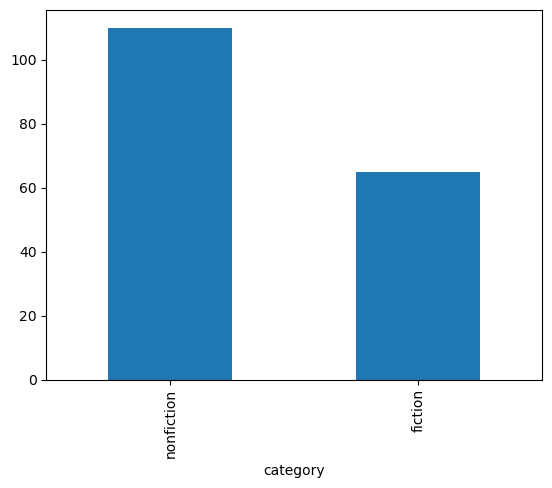

In [11]:
df_books["category"].value_counts().plot.bar()

### **Experiment (TF-IDF)**

In [12]:
from sklearn.feature_extraction.text import TfidfVectorizer
corpus = df_books["text"]

In [13]:
v = TfidfVectorizer()
transformed_output = v.fit_transform(corpus)
print(v.vocabulary_)

{'soumission': 6168, 'dans': 1645, 'une': 6929, 'france': 2702, 'assez': 483, 'proche': 5155, 'de': 1675, 'la': 3786, 'nôtre': 4575, 'un': 6895, 'homme': 3196, 'engage': 2226, 'carrière': 1019, 'universitaire': 6960, 'peu': 4913, 'motivé': 4381, 'par': 4793, 'enseignement': 2251, 'il': 3304, 'attend': 517, 'vie': 7086, 'ennuyeuse': 2247, 'mais': 4062, 'calme': 972, 'protégée': 5205, 'des': 1797, 'grands': 2910, 'drames': 2015, 'historiques': 3169, 'cependant': 1071, 'les': 3881, 'forces': 2649, 'en': 2195, 'jeu': 3635, 'le': 3845, 'pays': 4856, 'ont': 4642, 'fissuré': 2585, 'système': 6497, 'politique': 5021, 'jusqu': 3699, 'provoquer': 5220, 'son': 6152, 'effondrement': 2120, 'cette': 1075, 'implosion': 3346, 'sans': 5749, 'soubresauts': 6162, 'vraie': 7130, 'révolution': 5707, 'se': 5814, 'développe': 2065, 'comme': 1310, 'mauvais': 4162, 'rêve': 5708, 'talent': 6512, 'auteur': 535, 'sa': 5709, 'force': 2647, 'visionnaire': 7112, 'nous': 4550, 'entraînent': 2264, 'sur': 6439, 'terrai

In [14]:
all_feature_names = v.get_feature_names_out()

for word in all_feature_names:
    indx = v.vocabulary_.get(word)
    print(f"{word} {v.idf_[indx]}")

000 4.561046082604051
01 5.477336814478207
10 4.561046082604051
100 4.561046082604051
101 5.477336814478207
11 4.7841896339182615
12 5.477336814478207
13 4.7841896339182615
14 5.477336814478207
15 5.477336814478207
150 4.7841896339182615
1599 5.477336814478207
16 5.477336814478207
1700s 5.477336814478207
1776 5.477336814478207
1800s 5.477336814478207
1884 5.477336814478207
1885in 5.477336814478207
1888 5.477336814478207
19 5.477336814478207
1904 5.477336814478207
1924 5.477336814478207
1933 5.477336814478207
1939in 5.477336814478207
1940s 5.477336814478207
1942 5.071871706370042
1944 5.477336814478207
1945 5.071871706370042
1946 5.477336814478207
1950s 5.071871706370042
1955 5.071871706370042
1958 5.477336814478207
1959 5.477336814478207
1960 5.477336814478207
1967 5.477336814478207
1970 5.477336814478207
1970s 5.071871706370042
1980 5.071871706370042
1980s 5.071871706370042
1986 5.477336814478207
1991 4.7841896339182615
1992 5.477336814478207
1997 5.477336814478207
1999 5.071871706370

### **Train-test split**

In [15]:
X = df_books["text"]
y = df_books["category"]

In [16]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, test_size=0.25, random_state=101)

### **TF-IDF**

In [17]:
v1 = TfidfVectorizer()
X_train_tfidf1 = v1.fit_transform(X_train)

In [18]:
X_test_tfidf1 = v1.transform(X_test)

The training table has 131 books.

In [19]:
X_train_tfidf1.shape

(131, 6259)

The test table has 44 books.

In [20]:
X_test_tfidf1.shape

(44, 6259)

### **Logistic Regression - first experiment**

Used a Logistic Regression Model without any additional features. 

In [21]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
model = LogisticRegression(max_iter=1000).fit(X_train_tfidf1, y_train)
pred = model.predict(X_test_tfidf1)

Compared the model's guesses with the real answers. It has an accuracy of 64%, which in theory seems satisfactory. However, the difference in recall between fiction and nonfiction books is major (0.06 vs 0.96).

In [22]:
print(classification_report(y_test, pred))

              precision    recall  f1-score   support

     fiction       0.50      0.06      0.11        16
  nonfiction       0.64      0.96      0.77        28

    accuracy                           0.64        44
   macro avg       0.57      0.51      0.44        44
weighted avg       0.59      0.64      0.53        44



We see that for almost any book, the model guessed that it is nonfiction. This is due to the fact that 64% of the books in the test sample are nonfiction.


In [23]:
names = list(model.classes_)
print(pd.DataFrame(confusion_matrix(y_test, pred), index=["true " + n for n in names], columns=names))

                 fiction  nonfiction
true fiction           1          15
true nonfiction        1          27


As seen below, the model leans more towards the nonfiction category, even when the book is fiction.

In [24]:
print("5 fiction books:")
print((X_test[y_test == "fiction"])[:5])
print("\nP(fiction, nonfiction) of the fiction books selected:\n", model.predict_proba(v1.transform((X_test[y_test == "fiction"])[:5])))

5 fiction books:
11    The First Hostage (J.B. Collins #2) “The presi...
0     Soumission Dans une France assez proche de la ...
64    Bright Lines A vibrant debut novel, set in Bro...
47    Atlas Shrugged This is the story of a man who ...
28    Mothering Sunday From the Booker Award winner:...
Name: text, dtype: object

P(fiction, nonfiction) of the fiction books selected:
 [[0.33675998 0.66324002]
 [0.47470429 0.52529571]
 [0.53825138 0.46174862]
 [0.36265763 0.63734237]
 [0.39793076 0.60206924]]


### **Logistic Regression - second experiment (with balanced class weights)**

For the second model, I chose the approach of using the class_weight parameter, with the intention of getting better results after the supervised learning.

In [25]:
model2 = LogisticRegression(max_iter=1000, class_weight="balanced").fit(X_train_tfidf1, y_train)
pred2 = model2.predict(X_test_tfidf1)

It is clear that the balanced model is better at guessing, with an accuracy of 77%, above the 63.6% baseline.

In [26]:
print(classification_report(y_test, pred2))

              precision    recall  f1-score   support

     fiction       0.80      0.50      0.62        16
  nonfiction       0.76      0.93      0.84        28

    accuracy                           0.77        44
   macro avg       0.78      0.71      0.73        44
weighted avg       0.78      0.77      0.76        44



Even though the second model guessed an additional nonfiction book to be fiction, the trade-off is worth it: it guessed 7 more fiction books correctly, compared to the first one. Still, 50% of books from this category are still perceived as nonfiction.

In [27]:
names = list(model2.classes_)
print(pd.DataFrame(confusion_matrix(y_test, pred2), index=["true " + n for n in names], columns=names))

                 fiction  nonfiction
true fiction           8           8
true nonfiction        2          26


By targeting the problem and looking at the model's decision regarding 5 fiction books, all the values are between 0.43 and 0.64, very near the 50% mark, meaning that it is indecisive. Even when it guessed correctly, it is not convinced.

In [28]:
print("5 fiction books:")
print((X_test[y_test == "fiction"])[:5])
print("\nP(fiction, nonfiction) of the fiction books selected:\n", model2.predict_proba(v1.transform((X_test[y_test == "fiction"])[:5])))

5 fiction books:
11    The First Hostage (J.B. Collins #2) “The presi...
0     Soumission Dans une France assez proche de la ...
64    Bright Lines A vibrant debut novel, set in Bro...
47    Atlas Shrugged This is the story of a man who ...
28    Mothering Sunday From the Booker Award winner:...
Name: text, dtype: object

P(fiction, nonfiction) of the fiction books selected:
 [[0.43236371 0.56763629]
 [0.58056074 0.41943926]
 [0.64284619 0.35715381]
 [0.46193469 0.53806531]
 [0.50038456 0.49961544]]


### **Logistic Regression - third experiment (with balanced class weights + stop words elimination)**

For experimental reasons, I attempted to remove the most common words in english ("the", "and", "for" etc.) to see if it would improve the accuracy, as my theory is that the model would focus more on words that have a higher probability of differentiating between fiction and nonfiction.

In [29]:
v2 = TfidfVectorizer(stop_words="english")
X_train_tfidf2 = v2.fit_transform(X_train)
X_test_tfidf2 = v2.transform(X_test)

As expected, there are fewer words in the dictionary.

In [30]:
X_train_tfidf2.shape

(131, 6007)

In [31]:
X_test_tfidf2.shape

(44, 6007)

In [32]:
model3 = LogisticRegression(max_iter=1000, class_weight="balanced").fit(X_train_tfidf2, y_train)
pred3 = model3.predict(X_test_tfidf2)

Accuracy improved from 77% to 80%, but the real analysis is done below.

In [33]:
print(classification_report(y_test, pred3))

              precision    recall  f1-score   support

     fiction       0.77      0.62      0.69        16
  nonfiction       0.81      0.89      0.85        28

    accuracy                           0.80        44
   macro avg       0.79      0.76      0.77        44
weighted avg       0.79      0.80      0.79        44



Overall, the improvement is slight. It lost another correctly guessed nonfiction book, but "won" at 2 additional fiction books at the same time.

In [34]:
names = list(model3.classes_)
print(pd.DataFrame(confusion_matrix(y_test, pred3), index=["true " + n for n in names], columns=names))

                 fiction  nonfiction
true fiction          10           6
true nonfiction        3          25


In [35]:
print("5 fiction books:")
print((X_test[y_test == "fiction"])[:5])
print("\nP(fiction, nonfiction) of the fiction books selected:\n", model3.predict_proba(v2.transform((X_test[y_test == "fiction"])[:5])))

5 fiction books:
11    The First Hostage (J.B. Collins #2) “The presi...
0     Soumission Dans une France assez proche de la ...
64    Bright Lines A vibrant debut novel, set in Bro...
47    Atlas Shrugged This is the story of a man who ...
28    Mothering Sunday From the Booker Award winner:...
Name: text, dtype: object

P(fiction, nonfiction) of the fiction books selected:
 [[0.43123797 0.56876203]
 [0.54002831 0.45997169]
 [0.58627968 0.41372032]
 [0.49766166 0.50233834]
 [0.52559838 0.47440162]]
